In [1]:

!pip -q install openpyxl scikit-learn seaborn xgboost plotly joblib


In [2]:

# ==============================
# 1. Import Libraries
# ==============================

import os
import zipfile
import warnings
from pathlib import Path

import requests
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px

from IPython.display import display
from plotly.subplots import make_subplots

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    silhouette_score
)

import joblib

# ==============================
# 2. Configuration
# ==============================

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
PREDICTION_DAYS = 90
N_CLUSTERS = 4

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.2f}"
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

# ==============================
# Download Online Retail II
# ==============================

DATA_DIR = Path("/content/customer_intelligence_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = DATA_DIR / "online_retail_ii.zip"
EXCEL_PATH = DATA_DIR / "online_retail_II.xlsx"

DATA_URL = (
    "https://archive.ics.uci.edu/static/public/502/"
    "online+retail+ii.zip"
)

if not EXCEL_PATH.exists():

    response = requests.get(DATA_URL, timeout=180)
    response.raise_for_status()

    ZIP_PATH.write_bytes(response.content)

    with zipfile.ZipFile(ZIP_PATH, "r") as archive:

        excel_files = [
            name for name in archive.namelist()
            if name.lower().endswith((".xlsx", ".xls"))
        ]

        if not excel_files:
            raise FileNotFoundError(
                "No Excel file found in the downloaded archive."
            )

        selected_file = excel_files[0]

        with archive.open(selected_file) as source:
            EXCEL_PATH.write_bytes(source.read())

print("Dataset downloaded successfully!")
print("Dataset path:", EXCEL_PATH)
print(
    "File size:",
    f"{EXCEL_PATH.stat().st_size / (1024**2):.2f} MB"
)


Dataset downloaded successfully!
Dataset path: /content/customer_intelligence_data/online_retail_II.xlsx
File size: 43.51 MB


In [4]:

# ==============================
# Load All Excel Sheets
# ==============================

all_sheets = pd.read_excel(
    EXCEL_PATH,
    sheet_name=None,
    engine="openpyxl"
)

print("Available sheets:")

for sheet_name, sheet_df in all_sheets.items():
    print(f"{sheet_name}: {sheet_df.shape}")

# Combine sheets
df = pd.concat(
    all_sheets.values(),
    ignore_index=True
)

# Standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.replace(r"\s+", "", regex=True)
)

print("\nCombined Dataset Shape:", df.shape)

display(df.head())


Available sheets:
Year 2009-2010: (525461, 8)
Year 2010-2011: (541910, 8)

Combined Dataset Shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [5]:

# ==============================
# Rename Dataset Columns
# ==============================

rename_map = {
    "InvoiceNo": "Invoice",
    "InvoiceNo.": "Invoice",
    "CustomerID": "Customer ID",
    "UnitPrice": "Price"
}

df.rename(columns=rename_map, inplace=True)

required_columns = [
    "Invoice",
    "StockCode",
    "Quantity",
    "InvoiceDate",
    "Price",
    "Customer ID",
    "Country"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing expected columns: {missing_columns}"
    )

print("Columns standardized successfully!")
print(df.columns.tolist())


Columns standardized successfully!
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [6]:

# ==============================
# Dataset Overview
# ==============================

print("Dataset Shape:", df.shape)

print("\nData Types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

print("\nRandom 5 Rows:")
display(
    df.sample(
        min(5, len(df)),
        random_state=RANDOM_STATE
    )
)


Dataset Shape: (1067371, 8)

Data Types:


,Data Type
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
Price,float64
Customer ID,float64
Country,object



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB

First 5 Rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom



Random 5 Rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
455941,532657,21314,SMALL GLASS HEART TRINKET POT,12,2010-11-14 11:10:00,2.10,"14,562.00",United Kingdom
826291,563214,22383,LUNCH BAG SUKI DESIGN,2,2011-08-14 12:56:00,1.65,"16,370.00",United Kingdom
191636,507597,22561,WOODEN SCHOOL COLOURING SET,12,2010-05-10 13:21:00,1.65,"17,700.00",United Kingdom
25864,491634,21588,RETRO SPOT GIANT TUBE MATCHES,1,2009-12-11 15:40:00,2.55,"17,841.00",United Kingdom
73233,496007,85232B,SET/3 RUSSIAN DOLL STACKING TINS,3,2010-01-28 12:32:00,4.95,"15,203.00",United Kingdom


In [7]:

# ==============================
# Missing Values Analysis
# ==============================

missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": df.isna().mean() * 100
}).sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary)

# Duplicate records
duplicate_count = df.duplicated().sum()

print(f"\nDuplicate Rows: {duplicate_count:,}")
print(
    f"Duplicate Percentage: "
    f"{duplicate_count / len(df) * 100:.2f}%"
)


,Missing_Count,Missing_Percentage
Customer ID,243007,22.77
Description,4382,0.41
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00



Duplicate Rows: 34,335
Duplicate Percentage: 3.22%


In [8]:

# ==============================
# Data Type Conversion
# ==============================

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

df["Quantity"] = pd.to_numeric(
    df["Quantity"],
    errors="coerce"
)

df["Price"] = pd.to_numeric(
    df["Price"],
    errors="coerce"
)

df["Customer ID"] = pd.to_numeric(
    df["Customer ID"],
    errors="coerce"
)

# Identify cancellation invoices
invoice_text = df["Invoice"].astype("string").str.strip()

df["IsCancellation"] = (
    invoice_text.str.upper().str.startswith("C", na=False)
)

print("Date Range:")
print("Start:", df["InvoiceDate"].min())
print("End:", df["InvoiceDate"].max())

print("\nCancellation Rows:", f"{df['IsCancellation'].sum():,}")
print("Missing Customer IDs:", f"{df['Customer ID'].isna().sum():,}")
print("Missing Invoice Dates:", f"{df['InvoiceDate'].isna().sum():,}")

print("\nQuantity Statistics:")
display(df["Quantity"].describe())

print("\nPrice Statistics:")
display(df["Price"].describe())


Date Range:
Start: 2009-12-01 07:45:00
End: 2011-12-09 12:50:00

Cancellation Rows: 19,494
Missing Customer IDs: 243,007
Missing Invoice Dates: 0

Quantity Statistics:


,Quantity
count,"1,067,371.00"
mean,9.94
std,172.71
min,"-80,995.00"
25%,1.00
50%,3.00
75%,10.00
max,"80,995.00"



Price Statistics:


,Price
count,"1,067,371.00"
mean,4.65
std,123.55
min,"-53,594.36"
25%,1.25
50%,2.10
75%,4.15
max,"38,970.00"


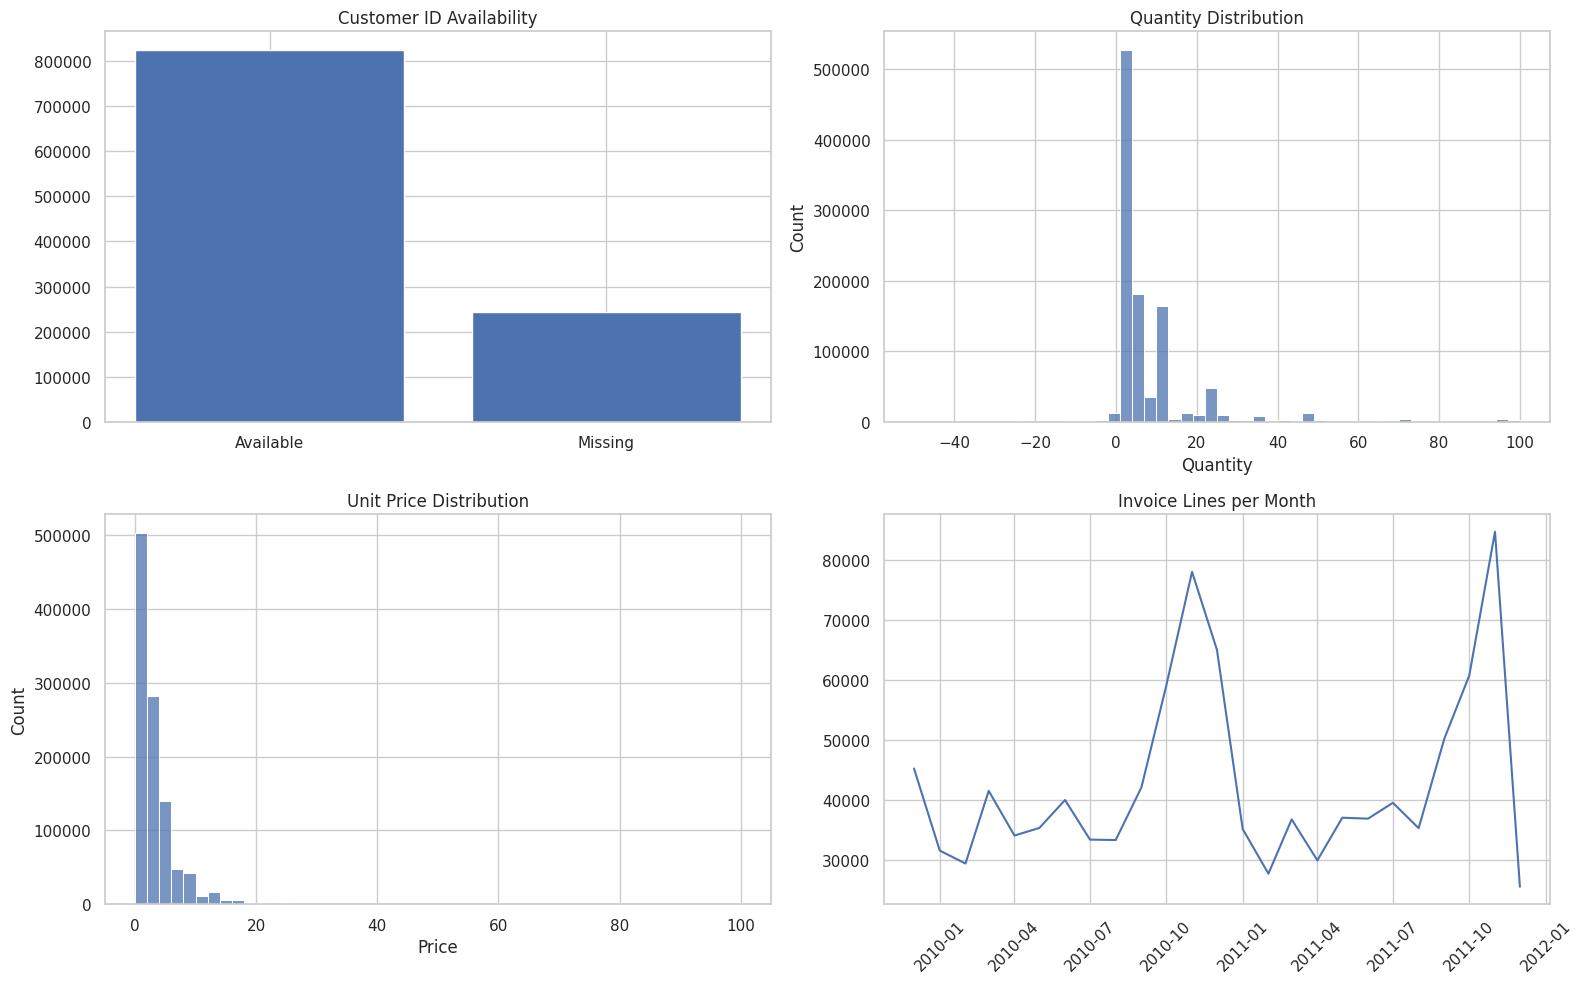

In [9]:

# ==============================
# Basic Exploratory Visualizations
# ==============================

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Customer ID availability
missing_customer = df["Customer ID"].isna().value_counts()

axes[0, 0].bar(
    ["Available", "Missing"],
    [
        missing_customer.get(False, 0),
        missing_customer.get(True, 0)
    ]
)

axes[0, 0].set_title("Customer ID Availability")

# 2. Quantity distribution
quantity_data = df.loc[
    df["Quantity"].between(-50, 100),
    "Quantity"
].dropna()

sns.histplot(
    quantity_data,
    bins=50,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Quantity Distribution")

# 3. Price distribution
price_data = df.loc[
    df["Price"].between(0, 100),
    "Price"
].dropna()

sns.histplot(
    price_data,
    bins=50,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Unit Price Distribution")

# 4. Monthly transaction lines
monthly_transactions = (
    df.dropna(subset=["InvoiceDate"])
    .set_index("InvoiceDate")
    .resample("MS")["Invoice"]
    .count()
)

axes[1, 1].plot(
    monthly_transactions.index,
    monthly_transactions.values
)

axes[1, 1].set_title("Invoice Lines per Month")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [10]:

# ==============================
# Prepare Valid Transaction Data
# ==============================

analysis_df = df.copy()

analysis_df["Revenue"] = (
    analysis_df["Quantity"] * analysis_df["Price"]
)

valid_rows = (
    analysis_df["InvoiceDate"].notna()
    & analysis_df["Quantity"].notna()
    & analysis_df["Price"].notna()
    & analysis_df["Invoice"].notna()
)

analysis_df = analysis_df.loc[valid_rows].copy()

# Keep positive sales transactions only
sales_df = analysis_df.loc[
    (~analysis_df["IsCancellation"])
    & (analysis_df["Quantity"] > 0)
    & (analysis_df["Price"] > 0)
].copy()

print("Original Rows:", f"{len(df):,}")
print("Valid Rows:", f"{len(analysis_df):,}")
print("Positive Sales Rows:", f"{len(sales_df):,}")

print(
    "Unique Identified Customers:",
    f"{sales_df['Customer ID'].nunique():,}"
)

print(
    "\nTotal Positive Sales Revenue:",
    f"£{sales_df['Revenue'].sum():,.2f}"
)

print("\nTop 10 Countries by Sales Lines:")

display(
    sales_df["Country"]
    .value_counts()
    .head(10)
    .rename_axis("Country")
    .reset_index(name="Sales_Lines")
)


Original Rows: 1,067,371
Valid Rows: 1,067,371
Positive Sales Rows: 1,041,670
Unique Identified Customers: 5,878

Total Positive Sales Revenue: £20,972,594.57

Top 10 Countries by Sales Lines:


,Country,Sales_Lines
0,United Kingdom,958501
1,EIRE,17349
2,Germany,16694
3,France,13940
4,Netherlands,5088
5,Spain,3719
6,Switzerland,3136
7,Belgium,3068
8,Portugal,2562
9,Australia,1812


In [11]:

# ==============================
# Customer-Level Dataset
# ==============================

customer_sales_df = sales_df.dropna(
    subset=["Customer ID"]
).copy()

customer_sales_df["Customer ID"] = (
    customer_sales_df["Customer ID"].astype("int64")
)

print(
    "Sales Rows with Identified Customers:",
    f"{len(customer_sales_df):,}"
)

print(
    "Unique Customers:",
    f"{customer_sales_df['Customer ID'].nunique():,}"
)

print(
    "Missing Customer IDs:",
    customer_sales_df["Customer ID"].isna().sum()
)

print(
    "Negative Quantity Rows:",
    (customer_sales_df["Quantity"] < 0).sum()
)

print(
    "Negative Revenue Rows:",
    (customer_sales_df["Revenue"] < 0).sum()
)


Sales Rows with Identified Customers: 805,549
Unique Customers: 5,878
Missing Customer IDs: 0
Negative Quantity Rows: 0
Negative Revenue Rows: 0


In [12]:

# ==============================
# RFM Feature Engineering
# ==============================

snapshot_date = (
    customer_sales_df["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

rfm = customer_sales_df.groupby("Customer ID").agg(
    Recency=(
        "InvoiceDate",
        lambda x: (snapshot_date - x.max()).days
    ),
    Frequency=(
        "Invoice",
        "nunique"
    ),
    Monetary=(
        "Revenue",
        "sum"
    )
).reset_index()

print("RFM Dataset Shape:", rfm.shape)

display(rfm.head(10))

print("\nRFM Statistical Summary:")
display(
    rfm[["Recency", "Frequency", "Monetary"]].describe()
)


RFM Dataset Shape: (5878, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346,326,12,"77,556.46"
1,12347,2,8,"5,633.32"
2,12348,75,5,"2,019.40"
3,12349,19,4,"4,428.69"
4,12350,310,1,334.40
5,12351,375,1,300.93
6,12352,36,10,"2,849.84"
7,12353,204,2,406.76
8,12354,232,1,"1,079.40"
9,12355,214,2,947.61



RFM Statistical Summary:


,Recency,Frequency,Monetary
count,"5,878.00","5,878.00","5,878.00"
mean,201.33,6.29,"3,018.62"
std,209.34,13.01,"14,737.73"
min,1.00,1.00,2.95
25%,26.00,1.00,348.76
50%,96.00,3.00,898.91
75%,380.00,7.00,"2,307.09"
max,739.00,398.00,"608,821.65"


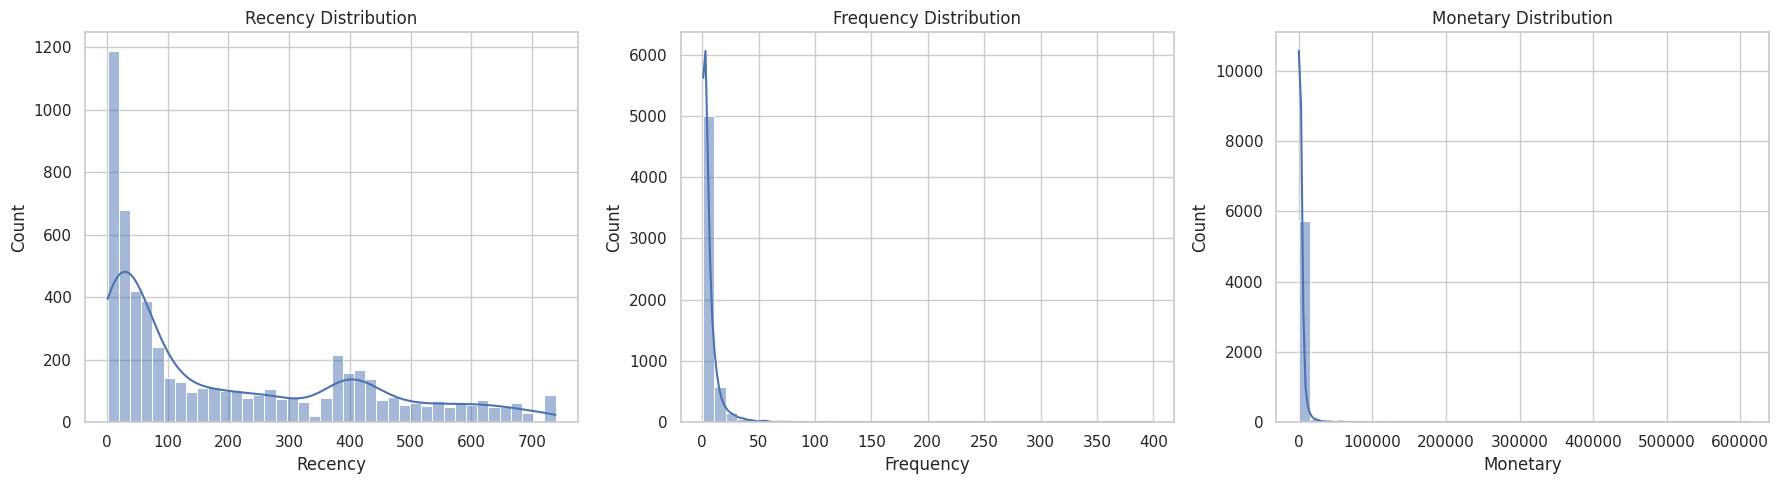

In [13]:

# ==============================
# RFM Distribution Analysis
# ==============================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = ["Recency", "Frequency", "Monetary"]

titles = [
    "Recency Distribution",
    "Frequency Distribution",
    "Monetary Distribution"
]

for ax, feature, title in zip(axes, features, titles):

    sns.histplot(
        rfm[feature],
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(title)

plt.tight_layout()
plt.show()


In [14]:

# ==============================
# RFM Diagnostic Analysis
# ==============================

print("RFM Dataset Shape:")
print(rfm.shape)

print("\nStatistical Summary:")
display(
    rfm[["Recency", "Frequency", "Monetary"]]
    .describe()
    .round(2)
)

print("\nFeature Skewness:")
display(
    rfm[["Recency", "Frequency", "Monetary"]]
    .skew()
    .round(2)
)

print("\nTop 10 Customers by Monetary:")
display(
    rfm.nlargest(10, "Monetary")
)

print("\nTop 10 Customers by Frequency:")
display(
    rfm.nlargest(10, "Frequency")
)


RFM Dataset Shape:
(5878, 4)

Statistical Summary:


,Recency,Frequency,Monetary
count,"5,878.00","5,878.00","5,878.00"
mean,201.33,6.29,"3,018.62"
std,209.34,13.01,"14,737.73"
min,1.00,1.00,2.95
25%,26.00,1.00,348.76
50%,96.00,3.00,898.92
75%,380.00,7.00,"2,307.09"
max,739.00,398.00,"608,821.65"



Feature Skewness:


,0
Recency,0.89
Frequency,12.64
Monetary,25.31



Top 10 Customers by Monetary:


,Customer ID,Recency,Frequency,Monetary
5692,18102,1,145,"608,821.65"
2277,14646,2,151,"528,602.52"
1789,14156,10,156,"313,946.37"
2538,14911,1,398,"295,972.63"
5050,17450,8,51,"246,973.09"
1331,13694,4,143,"196,482.81"
5109,17511,3,60,"175,603.55"
4061,16446,1,2,"168,472.50"
4295,16684,4,55,"147,142.77"
68,12415,24,28,"144,458.37"



Top 10 Customers by Frequency:


,Customer ID,Recency,Frequency,Monetary
2538,14911,1,398,"295,972.63"
400,12748,1,336,"56,599.39"
5433,17841,2,211,"70,884.07"
2935,15311,1,208,"116,771.16"
739,13089,3,203,"116,737.86"
2237,14606,1,192,"30,861.06"
1789,14156,10,156,"313,946.37"
5442,17850,372,155,"56,600.08"
2277,14646,2,151,"528,602.52"
5692,18102,1,145,"608,821.65"


In [15]:

# ==============================
# Log Transformation
# ==============================

rfm_log = np.log1p(
    rfm[["Recency", "Frequency", "Monetary"]]
)

print("Skewness Before Transformation:")
display(
    rfm[["Recency", "Frequency", "Monetary"]]
    .skew()
    .round(3)
)

print("\nSkewness After Transformation:")
display(
    rfm_log.skew().round(3)
)

print("\nTransformed Data:")
display(rfm_log.head())


Skewness Before Transformation:


,0
Recency,0.89
Frequency,12.64
Monetary,25.31



Skewness After Transformation:


,0
Recency,-0.49
Frequency,1.00
Monetary,0.27



Transformed Data:


,Recency,Frequency,Monetary
0,5.79,2.56,11.26
1,1.10,2.20,8.64
2,4.33,1.79,7.61
3,3.00,1.61,8.40
4,5.74,0.69,5.82


In [16]:

# ==============================
# Feature Scaling
# ==============================

scaler = StandardScaler()

rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_log),
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

print("Scaled RFM Sample:")
display(rfm_scaled.head())

print("\nFeature Means:")
display(rfm_scaled.mean().round(3))

print("\nFeature Standard Deviations:")
display(rfm_scaled.std().round(3))


Scaled RFM Sample:


,Recency,Frequency,Monetary
0,0.86,1.25,3.19
1,-2.15,0.80,1.30
2,-0.08,0.30,0.56
3,-0.94,0.07,1.12
4,0.82,-1.06,-0.74



Feature Means:


,0
Recency,-0.00
Frequency,0.00
Monetary,-0.00



Feature Standard Deviations:


,0
Recency,1.00
Frequency,1.00
Monetary,1.00


In [17]:

# ==============================
# Elbow Method & Silhouette Score
# ==============================

inertia_values = []
silhouette_values = []

K_RANGE = range(2, 11)

for k in K_RANGE:

    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    inertia_values.append(kmeans.inertia_)

    score = silhouette_score(
        rfm_scaled,
        labels,
        sample_size=2000,
        random_state=RANDOM_STATE
    )

    silhouette_values.append(score)

    print(
        f"K={k} | "
        f"Inertia={kmeans.inertia_:.2f} | "
        f"Silhouette={score:.4f}"
    )


K=2 | Inertia=8588.81 | Silhouette=0.4343
K=3 | Inertia=6351.98 | Silhouette=0.3458
K=4 | Inertia=4918.64 | Silhouette=0.3649
K=5 | Inertia=4097.83 | Silhouette=0.3462
K=6 | Inertia=3552.98 | Silhouette=0.3354
K=7 | Inertia=3184.84 | Silhouette=0.3075
K=8 | Inertia=2891.60 | Silhouette=0.2925
K=9 | Inertia=2650.60 | Silhouette=0.2864
K=10 | Inertia=2455.91 | Silhouette=0.2856


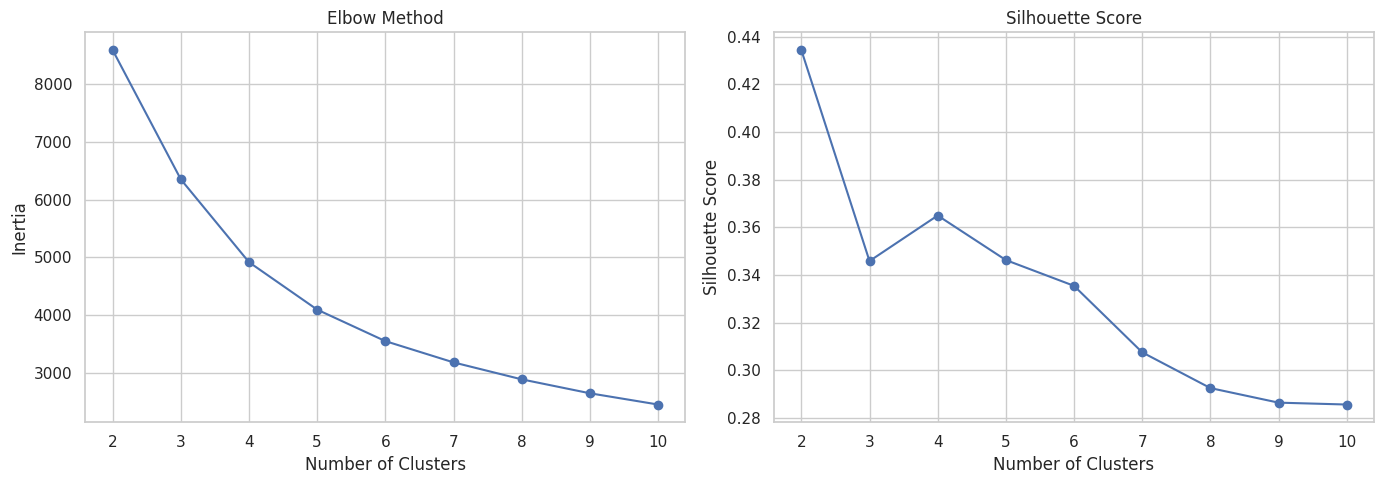

In [18]:

# ==============================
# Clustering Evaluation Plots
# ==============================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    list(K_RANGE),
    inertia_values,
    marker="o"
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(K_RANGE))

axes[1].plot(
    list(K_RANGE),
    silhouette_values,
    marker="o"
)

axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(K_RANGE))

plt.tight_layout()
plt.show()


In [19]:

# ==============================
# Final K-Means Model
# ==============================

final_kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    n_init=20
)

rfm["Cluster"] = final_kmeans.fit_predict(rfm_scaled)

print("K-Means Training Completed!")

print("\nCluster Distribution:")
display(
    rfm["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Customers")
    .to_frame()
)

print("\nCluster Percentages:")
display(
    (
        rfm["Cluster"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2).rename("Percentage").to_frame()
)


K-Means Training Completed!

Cluster Distribution:


,Customers
Cluster,
0,1188
1,1974
2,1465
3,1251



Cluster Percentages:


,Percentage
Cluster,
0,20.21
1,33.58
2,24.92
3,21.28


In [20]:

# ==============================
# Detailed Cluster Profiles
# ==============================

cluster_profile = rfm.groupby("Cluster").agg(
    Customers=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Median_Recency=("Recency", "median"),
    Avg_Frequency=("Frequency", "mean"),
    Median_Frequency=("Frequency", "median"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median"),
    Total_Revenue=("Monetary", "sum")
).round(2)

cluster_profile["Customer_Share"] = (
    cluster_profile["Customers"] / len(rfm) * 100
)

cluster_profile["Revenue_Share"] = (
    cluster_profile["Total_Revenue"]
    / rfm["Monetary"].sum() * 100
)

cluster_profile = cluster_profile.round(2)

display(cluster_profile)


,Customers,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Total_Revenue,Customer_Share,Revenue_Share
Cluster,,,,,,,,,,
0,1188,27.43,16.50,19.34,13.00,"11,014.37","5,126.80","13,085,069.69",20.21,73.75
1,1974,395.86,404.00,1.38,1.00,325.75,283.58,"643,026.91",33.58,3.62
2,1465,227.87,185.00,5.10,5.00,"2,002.10","1,509.04","2,933,080.13",24.92,16.53
3,1251,28.44,24.00,3.04,3.00,865.11,743.17,"1,082,252.45",21.28,6.10


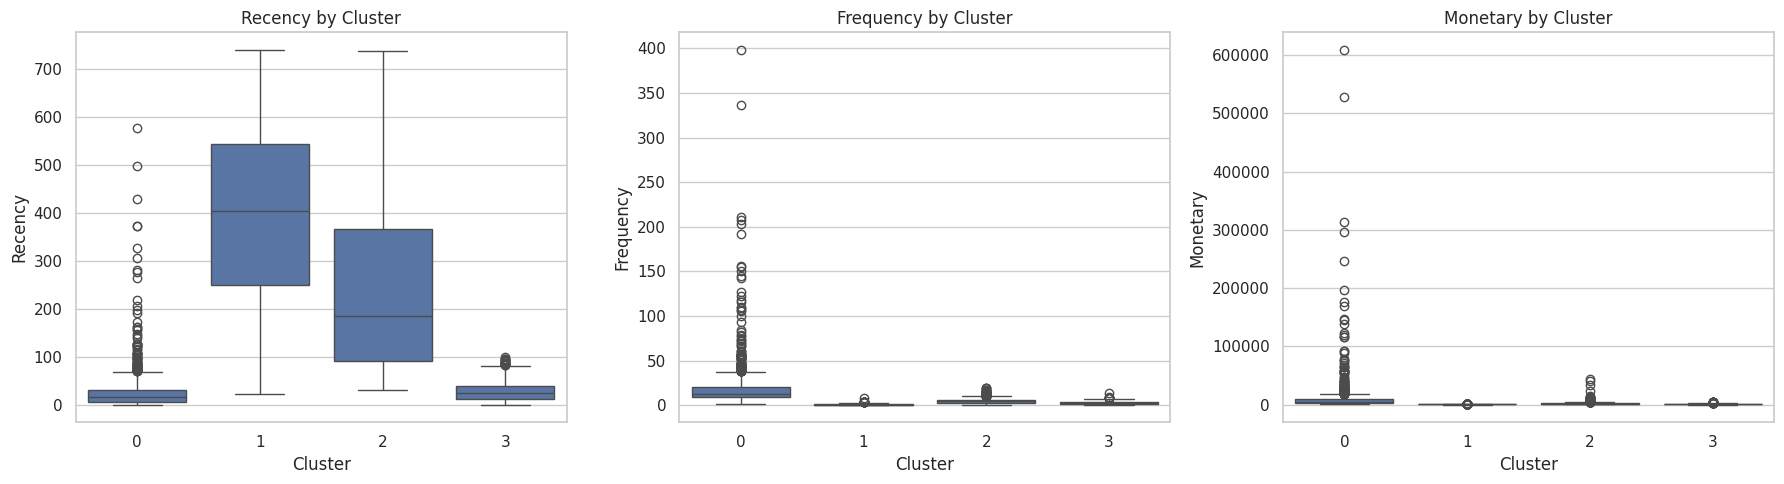

In [21]:

# ==============================
# Cluster Visualization
# ==============================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = ["Recency", "Frequency", "Monetary"]

for ax, feature in zip(axes, features):

    sns.boxplot(
        data=rfm,
        x="Cluster",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} by Cluster")

plt.tight_layout()
plt.show()


In [22]:

# ==============================
# Business Segment Mapping
# ==============================

segment_names = {
    0: "Champions",
    1: "Hibernating Customers",
    2: "At-Risk Customers",
    3: "Recent / Developing Customers"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

print("Segment Mapping:")
display(
    rfm[["Customer ID", "Cluster", "Segment"]].head()
)


Segment Mapping:


,Customer ID,Cluster,Segment
0,12346,0,Champions
1,12347,0,Champions
2,12348,2,At-Risk Customers
3,12349,3,Recent / Developing Customers
4,12350,1,Hibernating Customers


In [23]:

# ==============================
# Revenue Analysis
# ==============================

revenue_analysis = rfm.groupby("Segment").agg(
    Customers=("Customer ID", "count"),
    Total_Revenue=("Monetary", "sum"),
    Avg_Revenue=("Monetary", "mean"),
    Median_Revenue=("Monetary", "median")
)

revenue_analysis["Customer_Share"] = (
    revenue_analysis["Customers"] / len(rfm) * 100
)

revenue_analysis["Revenue_Share"] = (
    revenue_analysis["Total_Revenue"]
    / rfm["Monetary"].sum() * 100
)

revenue_analysis = revenue_analysis.round(2)

display(revenue_analysis)


,Customers,Total_Revenue,Avg_Revenue,Median_Revenue,Customer_Share,Revenue_Share
Segment,,,,,,
At-Risk Customers,1465,"2,933,080.13","2,002.10","1,509.04",24.92,16.53
Champions,1188,"13,085,069.69","11,014.37","5,126.80",20.21,73.75
Hibernating Customers,1974,"643,026.91",325.75,283.58,33.58,3.62
Recent / Developing Customers,1251,"1,082,252.45",865.11,743.17,21.28,6.10


In [24]:

# ==============================
# Segmentation Dashboard
# ==============================

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Customer Distribution",
        "Revenue Contribution",
        "Average Customer Spending",
        "Total Revenue by Segment"
    ),
    specs=[
        [{"type": "pie"}, {"type": "bar"}],
        [{"type": "bar"}, {"type": "bar"}]
    ]
)

segments = revenue_analysis.index

# 1. Customer Distribution
fig.add_trace(
    go.Pie(
        labels=segments,
        values=revenue_analysis["Customers"],
        hole=0.4
    ),
    row=1,
    col=1
)

# 2. Revenue Contribution
fig.add_trace(
    go.Bar(
        x=segments,
        y=revenue_analysis["Revenue_Share"],
        name="Revenue Share",
        text=revenue_analysis["Revenue_Share"].round(2),
        textposition="auto"
    ),
    row=1,
    col=2
)

# 3. Average Customer Spending
fig.add_trace(
    go.Bar(
        x=segments,
        y=revenue_analysis["Avg_Revenue"],
        name="Average Revenue",
        text=revenue_analysis["Avg_Revenue"].round(2),
        textposition="auto"
    ),
    row=2,
    col=1
)

# 4. Total Revenue
fig.add_trace(
    go.Bar(
        x=segments,
        y=revenue_analysis["Total_Revenue"],
        name="Total Revenue",
        text=revenue_analysis["Total_Revenue"].round(0),
        textposition="auto"
    ),
    row=2,
    col=2
)

fig.update_layout(
    title="Customer Segmentation Dashboard",
    height=850,
    template="plotly_white",
    showlegend=False
)

fig.update_yaxes(
    title_text="Revenue Share (%)",
    row=1,
    col=2
)

fig.update_yaxes(
    title_text="Average Revenue (£)",
    row=2,
    col=1
)

fig.update_yaxes(
    title_text="Total Revenue (£)",
    row=2,
    col=2
)

fig.show()


In [25]:

# ==============================
# Export Segmentation Results
# ==============================

rfm.to_csv(
    "Customer_Segmentation_Results.csv",
    index=False
)

cluster_profile.to_csv(
    "Cluster_Profile.csv"
)

revenue_analysis.to_csv(
    "Revenue_Analysis.csv"
)

fig.write_html(
    "Customer_Intelligence_Dashboard.html",
    include_plotlyjs=True
)

print("All segmentation files exported successfully!")


All segmentation files exported successfully!


In [26]:

# ==============================
# Define Observation & Prediction Periods
# ==============================

data = customer_sales_df.copy()

data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])

max_date = data["InvoiceDate"].max()

cutoff_date = (
    max_date - pd.Timedelta(days=PREDICTION_DAYS)
)

print("Last Transaction Date:", max_date)
print("Cutoff Date:", cutoff_date)
print("Prediction Period:", PREDICTION_DAYS, "days")


Last Transaction Date: 2011-12-09 12:50:00
Cutoff Date: 2011-09-10 12:50:00
Prediction Period: 90 days


In [27]:

# ==============================
# Customer Feature Engineering
# ==============================

observation_data = data.loc[
    data["InvoiceDate"] < cutoff_date
].copy()

customer_features = observation_data.groupby("Customer ID").agg(
    Recency=(
        "InvoiceDate",
        lambda x: (cutoff_date - x.max()).days
    ),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Unique_Products=("StockCode", "nunique")
).reset_index()

customer_features["Avg_Order_Value"] = (
    customer_features["Monetary"]
    / customer_features["Frequency"]
)

print("Observation Data Shape:", observation_data.shape)
print("Customer Features Shape:", customer_features.shape)

display(customer_features.head())


Observation Data Shape: (644022, 10)
Customer Features Shape: (5281, 7)


,Customer ID,Recency,Frequency,Monetary,Total_Quantity,Unique_Products,Avg_Order_Value
0,12346,235,12,"77,556.46",74285,27,"6,463.04"
1,12347,39,6,"4,114.18",2418,107,685.70
2,12348,158,4,"1,709.40",2497,25,427.35
3,12349,317,3,"2,671.14",993,90,890.38
4,12350,219,1,334.40,197,17,334.40


In [28]:

# ==============================
# Create Future Purchase Target
# ==============================

future_data = data.loc[
    (data["InvoiceDate"] >= cutoff_date)
    & (data["InvoiceDate"] <= max_date)
].copy()

future_customers = future_data["Customer ID"].unique()

customer_features["Purchased_Next_90_Days"] = (
    customer_features["Customer ID"]
    .isin(future_customers)
    .astype(int)
)

print("Target Distribution:")
display(
    customer_features["Purchased_Next_90_Days"]
    .value_counts()
    .rename_axis("Purchased")
    .to_frame("Customers")
)

print("\nTarget Percentage:")
display(
    (
        customer_features["Purchased_Next_90_Days"]
        .value_counts(normalize=True) * 100
    ).round(2)
)


Target Distribution:


,Customers
Purchased,
0,2989
1,2292



Target Percentage:


,proportion
Purchased_Next_90_Days,
0,56.60
1,43.40


In [29]:

# ==============================
# Prepare Features & Target
# ==============================

model_data = customer_features.drop(
    columns=["Customer ID"]
).copy()

X = model_data.drop(
    columns=["Purchased_Next_90_Days"]
)

y = model_data["Purchased_Next_90_Days"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())


Features Shape: (5281, 6)
Target Shape: (5281,)


,Recency,Frequency,Monetary,Total_Quantity,Unique_Products,Avg_Order_Value
0,235,12,"77,556.46",74285,27,"6,463.04"
1,39,6,"4,114.18",2418,107,685.70
2,158,4,"1,709.40",2497,25,427.35
3,317,3,"2,671.14",993,90,890.38
4,219,1,334.40,197,17,334.40


In [30]:

# ==============================
# Split Dataset
# ==============================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
display(
    (y_train.value_counts(normalize=True) * 100).round(2)
)

print("\nTesting Target Distribution:")
display(
    (y_test.value_counts(normalize=True) * 100).round(2)
)


Training Features: (4224, 6)
Testing Features: (1057, 6)

Training Target Distribution:


,proportion
Purchased_Next_90_Days,
0,56.61
1,43.39



Testing Target Distribution:


,proportion
Purchased_Next_90_Days,
0,56.58
1,43.42


In [31]:

# ==============================
# Logistic Regression Model
# ==============================

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [32]:

# ==============================
# Random Forest Model
# ==============================

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [33]:

# ==============================
# XGBoost Model
# ==============================

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost trained successfully!")


XGBoost trained successfully!


In [34]:

# ==============================
# Model Comparison
# ==============================

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgb_model
}

model_results = []

model_probabilities = {}

for model_name, model in models.items():

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    model_probabilities[model_name] = probabilities

    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "PR_AUC": average_precision_score(y_test, probabilities)
    })

model_comparison = pd.DataFrame(model_results)

model_comparison = model_comparison.sort_values(
    by="ROC_AUC",
    ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Logistic Regression,0.72,0.70,0.64,0.67,0.79,0.76
1,XGBoost,0.72,0.69,0.63,0.66,0.78,0.74
2,Random Forest,0.72,0.70,0.62,0.66,0.78,0.73


In [35]:

# ==============================
# Detailed Model Evaluation
# ==============================

for model_name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Precision:", round(precision_score(y_test, predictions), 4))
    print("Recall:", round(recall_score(y_test, predictions), 4))
    print("F1 Score:", round(f1_score(y_test, predictions), 4))
    print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))
    print("PR-AUC:", round(average_precision_score(y_test, probabilities), 4))

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))

    print("Confusion Matrix:")
    display(
        pd.DataFrame(
            confusion_matrix(y_test, predictions),
            index=["Actual 0", "Actual 1"],
            columns=["Predicted 0", "Predicted 1"]
        )
    )



Logistic Regression
Accuracy: 0.7247
Precision: 0.7
Recall: 0.6405
F1 Score: 0.6689
ROC-AUC: 0.7945
PR-AUC: 0.7602

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.79      0.76       598
           1       0.70      0.64      0.67       459

    accuracy                           0.72      1057
   macro avg       0.72      0.71      0.72      1057
weighted avg       0.72      0.72      0.72      1057

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,472,126
Actual 1,165,294



Random Forest
Accuracy: 0.72
Precision: 0.7002
Recall: 0.6209
F1 Score: 0.6582
ROC-AUC: 0.7815
PR-AUC: 0.7293

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.80      0.76       598
           1       0.70      0.62      0.66       459

    accuracy                           0.72      1057
   macro avg       0.72      0.71      0.71      1057
weighted avg       0.72      0.72      0.72      1057

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,476,122
Actual 1,174,285



XGBoost
Accuracy: 0.7171
Precision: 0.6905
Recall: 0.6318
F1 Score: 0.6598
ROC-AUC: 0.7832
PR-AUC: 0.7422

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.78      0.76       598
           1       0.69      0.63      0.66       459

    accuracy                           0.72      1057
   macro avg       0.71      0.71      0.71      1057
weighted avg       0.72      0.72      0.72      1057

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,468,130
Actual 1,169,290


In [39]:

# ==============================
# Logistic Regression Coefficients
# ==============================

coefficients = logistic_model.named_steps["model"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    by="Absolute_Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))


,Feature,Coefficient,Absolute_Importance
0,Recency,-0.82,0.82
1,Frequency,0.70,0.70
2,Unique_Products,0.38,0.38
3,Monetary,-0.07,0.07
4,Avg_Order_Value,0.02,0.02
5,Total_Quantity,0.01,0.01


In [40]:

# ==============================
# Feature Coefficients Chart
# ==============================

feature_plot = feature_importance.sort_values(
    "Coefficient"
)

fig = px.bar(
    feature_plot,
    x="Coefficient",
    y="Feature",
    orientation="h",
    color="Coefficient",
    color_continuous_scale="RdBu",
    title="Logistic Regression - Feature Coefficients"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Standardized Coefficient",
    yaxis_title="Customer Features"
)

fig.show()


In [41]:

# ==============================
# Train / Validation Split
# ==============================

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("Model Training Set:", X_fit.shape)
print("Validation Set:", X_val.shape)


Model Training Set: (3379, 6)
Validation Set: (845, 6)


In [42]:

# ==============================
# Validation Logistic Regression
# ==============================

threshold_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

threshold_model.fit(X_fit, y_fit)

print("Validation model trained successfully!")


Validation model trained successfully!


In [43]:

# ==============================
# Threshold Optimization
# ==============================

val_prob = threshold_model.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.05):

    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1_Score": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

display(threshold_results.round(4))

best_threshold = threshold_results.loc[
    threshold_results["F1_Score"].idxmax(),
    "Threshold"
]

print("Selected Threshold:", best_threshold)


,Threshold,Precision,Recall,F1_Score
0,0.30,0.54,0.84,0.66
1,0.35,0.58,0.81,0.67
2,0.40,0.62,0.78,0.69
3,0.45,0.64,0.73,0.68
4,0.50,0.66,0.65,0.66
5,0.55,0.71,0.57,0.63
6,0.60,0.73,0.45,0.56
7,0.65,0.77,0.38,0.51
8,0.70,0.83,0.31,0.45


Selected Threshold: 0.4


In [44]:

# ==============================
# Final Model Training
# ==============================

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

final_model.fit(X_train, y_train)

print("Final Logistic Regression Model trained successfully!")


Final Logistic Regression Model trained successfully!


In [45]:

# ==============================
# Final Model Evaluation
# ==============================

final_prob = final_model.predict_proba(X_test)[:, 1]

final_pred = (
    final_prob >= best_threshold
).astype(int)

final_metrics = {
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, final_pred),
    "Precision": precision_score(
        y_test, final_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, final_pred, zero_division=0
    ),
    "F1_Score": f1_score(
        y_test, final_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, final_prob),
    "PR_AUC": average_precision_score(y_test, final_prob)
}

print("Final Model Results:")
display(
    pd.DataFrame([final_metrics]).round(4)
)

print("\nClassification Report:")
print(classification_report(y_test, final_pred))

print("Confusion Matrix:")
display(
    pd.DataFrame(
        confusion_matrix(y_test, final_pred),
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    )
)


Final Model Results:


,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,0.40,0.72,0.64,0.77,0.70,0.79,0.76



Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.67      0.73       598
           1       0.64      0.77      0.70       459

    accuracy                           0.72      1057
   macro avg       0.72      0.72      0.71      1057
weighted avg       0.73      0.72      0.72      1057

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,403,195
Actual 1,106,353


In [46]:

# ==============================
# Save Final Purchase Prediction Model
# ==============================

joblib.dump(
    final_model,
    "Customer_Purchase_Prediction_Model.pkl"
)

print("Final model saved successfully!")


Final model saved successfully!


In [47]:

# ==============================
# Export Customer Predictions
# ==============================

test_predictions = pd.DataFrame({
    "Customer ID": customer_features.loc[
        X_test.index, "Customer ID"
    ].values,

    "Actual_Purchase": y_test.values,

    "Purchase_Probability": final_prob,

    "Predicted_Purchase": final_pred
})

test_predictions["Predicted_Segment"] = (
    test_predictions["Predicted_Purchase"].map({
        0: "Not Expected to Purchase",
        1: "Expected to Purchase"
    })
)

test_predictions.to_csv(
    "Customer_Purchase_Predictions.csv",
    index=False
)

display(test_predictions.head(10))

print("Predictions exported successfully!")


,Customer ID,Actual_Purchase,Purchase_Probability,Predicted_Purchase,Predicted_Segment
0,13687,0,0.29,0,Not Expected to Purchase
1,17857,1,0.74,1,Expected to Purchase
2,17611,1,0.98,1,Expected to Purchase
3,16483,0,0.42,1,Expected to Purchase
4,15170,0,0.20,0,Not Expected to Purchase
5,14074,0,0.08,0,Not Expected to Purchase
6,12494,1,0.60,1,Expected to Purchase
7,17486,0,0.35,0,Not Expected to Purchase
8,17935,0,0.63,1,Expected to Purchase
9,17124,0,0.44,1,Expected to Purchase


Predictions exported successfully!


In [48]:

# ==============================
# Export Model Comparison
# ==============================

model_comparison.to_csv(
    "Model_Comparison.csv",
    index=False
)

print("Model comparison exported successfully!")


Model comparison exported successfully!


In [49]:

# ==============================
# Historical RFM
# ==============================

historical_rfm = observation_data.groupby("Customer ID").agg(
    Recency=(
        "InvoiceDate",
        lambda x: (cutoff_date - x.max()).days
    ),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("Historical RFM Shape:", historical_rfm.shape)

display(historical_rfm.head())


Historical RFM Shape: (5281, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346,235,12,"77,556.46"
1,12347,39,6,"4,114.18"
2,12348,158,4,"1,709.40"
3,12349,317,3,"2,671.14"
4,12350,219,1,334.40


In [50]:

# ==============================
# Historical K-Means Segmentation
# ==============================

historical_rfm_log = np.log1p(
    historical_rfm[
        ["Recency", "Frequency", "Monetary"]
    ]
)

historical_scaler = StandardScaler()

historical_rfm_scaled = historical_scaler.fit_transform(
    historical_rfm_log
)

historical_kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    n_init=20
)

historical_rfm["Cluster"] = (
    historical_kmeans.fit_predict(historical_rfm_scaled)
)

print("Historical Segmentation Completed!")

print("\nCluster Distribution:")
display(
    historical_rfm["Cluster"]
    .value_counts()
    .sort_index()
)


Historical Segmentation Completed!

Cluster Distribution:


,count
Cluster,
0,662
1,2121
2,1604
3,894


In [51]:

# ==============================
# Historical Cluster Profiles
# ==============================

historical_cluster_profile = historical_rfm.groupby(
    "Cluster"
).agg(
    Customers=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Median_Recency=("Recency", "median"),
    Avg_Frequency=("Frequency", "mean"),
    Median_Frequency=("Frequency", "median"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median")
).round(2)

display(historical_cluster_profile)


,Customers,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary
Cluster,,,,,,,
0,662,32.00,26.00,2.70,2.00,741.84,605.31
1,2121,344.11,327.00,1.42,1.00,351.51,301.54
2,1604,197.28,166.00,5.16,5.00,"2,067.60","1,502.28"
3,894,30.40,19.00,19.32,14.00,"10,888.52","5,244.41"


In [52]:

# ==============================
# Historical Segment Names
# ==============================

historical_segment_names = {
    0: "Recent / Developing Customers",
    1: "Hibernating Customers",
    2: "At-Risk Customers",
    3: "Champions"
}

historical_rfm["Segment"] = (
    historical_rfm["Cluster"]
    .map(historical_segment_names)
)

display(
    historical_rfm[
        ["Customer ID", "Cluster", "Segment"]
    ].head()
)


,Customer ID,Cluster,Segment
0,12346,3,Champions
1,12347,3,Champions
2,12348,2,At-Risk Customers
3,12349,2,At-Risk Customers
4,12350,1,Hibernating Customers


In [53]:

# ==============================
# Combine Predictions & Segments
# ==============================

historical_predictions = test_predictions.merge(
    historical_rfm[
        ["Customer ID", "Cluster", "Segment"]
    ],
    on="Customer ID",
    how="left",
    validate="one_to_one"
)

print("Combined Dataset Shape:", historical_predictions.shape)

print(
    "Missing Segments:",
    historical_predictions["Segment"].isna().sum()
)

display(historical_predictions.head(10))


Combined Dataset Shape: (1057, 7)
Missing Segments: 0


,Customer ID,Actual_Purchase,Purchase_Probability,Predicted_Purchase,Predicted_Segment,Cluster,Segment
0,13687,0,0.29,0,Not Expected to Purchase,2,At-Risk Customers
1,17857,1,0.74,1,Expected to Purchase,3,Champions
2,17611,1,0.98,1,Expected to Purchase,3,Champions
3,16483,0,0.42,1,Expected to Purchase,1,Hibernating Customers
4,15170,0,0.20,0,Not Expected to Purchase,1,Hibernating Customers
5,14074,0,0.08,0,Not Expected to Purchase,1,Hibernating Customers
6,12494,1,0.60,1,Expected to Purchase,2,At-Risk Customers
7,17486,0,0.35,0,Not Expected to Purchase,1,Hibernating Customers
8,17935,0,0.63,1,Expected to Purchase,2,At-Risk Customers
9,17124,0,0.44,1,Expected to Purchase,1,Hibernating Customers


In [54]:

# ==============================
# Segment Purchase Analysis
# ==============================

historical_segment_analysis = (
    historical_predictions.groupby(
        ["Cluster", "Segment"],
        sort=True
    ).agg(
        Customers=("Customer ID", "count"),
        Actual_Buyers=("Actual_Purchase", "sum"),
        Predicted_Buyers=("Predicted_Purchase", "sum"),
        Average_Purchase_Probability=(
            "Purchase_Probability", "mean"
        )
    ).reset_index()
)

historical_segment_analysis["Actual_Purchase_Rate"] = (
    historical_segment_analysis["Actual_Buyers"]
    / historical_segment_analysis["Customers"] * 100
)

historical_segment_analysis["Predicted_Purchase_Rate"] = (
    historical_segment_analysis["Predicted_Buyers"]
    / historical_segment_analysis["Customers"] * 100
)

# Convert average probability to percentage
historical_segment_analysis[
    "Average_Purchase_Probability"
] *= 100

historical_segment_analysis = (
    historical_segment_analysis.round(2)
)

display(historical_segment_analysis)


,Cluster,Segment,Customers,Actual_Buyers,Predicted_Buyers,Average_Purchase_Probability,Actual_Purchase_Rate,Predicted_Purchase_Rate
0,0,Recent / Developing Customers,129,70,129,55.01,54.26,100.00
1,1,Hibernating Customers,429,84,42,22.32,19.58,9.79
2,2,At-Risk Customers,326,162,204,46.14,49.69,62.58
3,3,Champions,173,143,173,81.56,82.66,100.00


In [55]:

# ==============================
# Export Historical Segment Analysis
# ==============================

historical_segment_analysis.to_csv(
    "Historical_Segment_Purchase_Analysis.csv",
    index=False
)

historical_cluster_profile.to_csv(
    "Historical_Cluster_Profile.csv"
)

print("Historical segment analysis exported successfully!")


Historical segment analysis exported successfully!


In [56]:

# ==============================
# Prepare Dashboard Data
# ==============================

dashboard_segments = historical_rfm.copy()

segment_revenue = dashboard_segments.groupby(
    "Segment",
    sort=False
).agg(
    Customers=("Customer ID", "count"),
    Total_Revenue=("Monetary", "sum"),
    Average_Revenue=("Monetary", "mean")
).reset_index()

dashboard_predictions = historical_segment_analysis.copy()

# Consistent segment order across all charts
segment_order = [
    "Champions",
    "At-Risk Customers",
    "Hibernating Customers",
    "Recent / Developing Customers"
]

segment_revenue["Segment"] = pd.Categorical(
    segment_revenue["Segment"],
    categories=segment_order,
    ordered=True
)

dashboard_predictions["Segment"] = pd.Categorical(
    dashboard_predictions["Segment"],
    categories=segment_order,
    ordered=True
)

segment_revenue = (
    segment_revenue.sort_values("Segment").reset_index(drop=True)
)

dashboard_predictions = (
    dashboard_predictions.sort_values("Segment").reset_index(drop=True)
)

print("Dashboard data prepared successfully!")

print("\nHistorical Revenue by Segment:")
display(segment_revenue.round(2))

print("\nPurchase Prediction by Segment:")
display(dashboard_predictions.round(2))


Dashboard data prepared successfully!

Historical Revenue by Segment:


,Segment,Customers,Total_Revenue,Average_Revenue
0,Champions,894,"9,734,335.21","10,888.52"
1,At-Risk Customers,1604,"3,316,428.88","2,067.60"
2,Hibernating Customers,2121,"745,543.19",351.51
3,Recent / Developing Customers,662,"491,101.17",741.84



Purchase Prediction by Segment:


,Cluster,Segment,Customers,Actual_Buyers,Predicted_Buyers,Average_Purchase_Probability,Actual_Purchase_Rate,Predicted_Purchase_Rate
0,3,Champions,173,143,173,81.56,82.66,100.00
1,2,At-Risk Customers,326,162,204,46.14,49.69,62.58
2,1,Hibernating Customers,429,84,42,22.32,19.58,9.79
3,0,Recent / Developing Customers,129,70,129,55.01,54.26,100.00


In [57]:

# ==============================
# Final Customer Intelligence Dashboard
# ==============================

# Prepare revenue share
revenue_plot = segment_revenue.copy()

revenue_plot["Revenue_Share"] = (
    revenue_plot["Total_Revenue"]
    / revenue_plot["Total_Revenue"].sum() * 100
)

# Create subplot structure
fig = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=(
        "Customer Distribution by Segment",
        "Revenue Contribution by Segment",
        "Average Revenue per Customer",
        "Actual vs Predicted Purchase Rate",
        "Average Purchase Probability",
        "Actual Buyers vs Predicted Buyers"
    ),
    specs=[
        [{"type": "pie"}, {"type": "bar"}],
        [{"type": "bar"}, {"type": "bar"}],
        [{"type": "bar"}, {"type": "bar"}]
    ],
    vertical_spacing=0.14,
    horizontal_spacing=0.12
)

# 1. Customer Distribution
fig.add_trace(
    go.Pie(
        labels=revenue_plot["Segment"],
        values=revenue_plot["Customers"],
        hole=0.4,
        showlegend=False,
        textinfo="label+percent",
        textposition="outside"
    ),
    row=1,
    col=1
)

# 2. Revenue Contribution
fig.add_trace(
    go.Bar(
        x=revenue_plot["Segment"],
        y=revenue_plot["Revenue_Share"],
        name="Revenue Share",
        text=revenue_plot["Revenue_Share"].round(1).astype(str) + "%",
        textposition="auto"
    ),
    row=1,
    col=2
)

# 3. Average Revenue per Customer
fig.add_trace(
    go.Bar(
        x=revenue_plot["Segment"],
        y=revenue_plot["Average_Revenue"],
        name="Average Revenue",
        text=revenue_plot["Average_Revenue"].round(0),
        textposition="auto"
    ),
    row=2,
    col=1
)

# 4. Actual vs Predicted Purchase Rate
fig.add_trace(
    go.Bar(
        x=dashboard_predictions["Segment"],
        y=dashboard_predictions["Actual_Purchase_Rate"],
        name="Actual Purchase Rate"
    ),
    row=2,
    col=2
)

fig.add_trace(
    go.Bar(
        x=dashboard_predictions["Segment"],
        y=dashboard_predictions["Predicted_Purchase_Rate"],
        name="Predicted Purchase Rate"
    ),
    row=2,
    col=2
)

# 5. Average Purchase Probability
fig.add_trace(
    go.Bar(
        x=dashboard_predictions["Segment"],
        y=dashboard_predictions[
            "Average_Purchase_Probability"
        ],
        name="Average Purchase Probability",
        text=dashboard_predictions[
            "Average_Purchase_Probability"
        ].round(1).astype(str) + "%",
        textposition="auto"
    ),
    row=3,
    col=1
)

# 6. Actual vs Predicted Buyers
fig.add_trace(
    go.Bar(
        x=dashboard_predictions["Segment"],
        y=dashboard_predictions["Actual_Buyers"],
        name="Actual Buyers"
    ),
    row=3,
    col=2
)

fig.add_trace(
    go.Bar(
        x=dashboard_predictions["Segment"],
        y=dashboard_predictions["Predicted_Buyers"],
        name="Predicted Buyers"
    ),
    row=3,
    col=2
)

# Dashboard layout
fig.update_layout(
    title={
        "text": "Customer Intelligence & Purchase Prediction Dashboard",
        "x": 0.5,
        "xanchor": "center",
        "y": 0.98,
        "font": {"size": 23}
    },
    height=1450,
    width=1600,
    template="plotly_white",
    barmode="group",
    legend=dict(
        orientation="h",
        yanchor="top",
        y=-0.12,
        xanchor="center",
        x=0.5,
        font=dict(size=11)
    ),
    margin=dict(
        t=120,
        b=180,
        l=90,
        r=70
    )
)

# Axis labels
fig.update_yaxes(title_text="Customers", row=1, col=1)
fig.update_yaxes(title_text="Revenue Share (%)", row=1, col=2)
fig.update_yaxes(title_text="Average Revenue (£)", row=2, col=1)
fig.update_yaxes(title_text="Purchase Rate (%)", row=2, col=2)
fig.update_yaxes(title_text="Probability (%)", row=3, col=1)
fig.update_yaxes(title_text="Number of Buyers", row=3, col=2)

# Improve readability
fig.update_annotations(font_size=15)

fig.update_yaxes(
    title_font_size=12,
    tickfont_size=10
)

fig.update_xaxes(
    tickangle=-15,
    tickfont_size=10
)

# Display dashboard
fig.show()


In [58]:

# ==============================
# Export Final Dashboard
# ==============================

fig.write_html(
    "Customer_Intelligence_Final_Dashboard.html",
    include_plotlyjs=True
)

print("Final dashboard exported successfully!")


Final dashboard exported successfully!


In [59]:

# ==============================
# Export Final Project Files
# ==============================

export_files = {
    "Customer_Segmentation_Results.csv": rfm,
    "Cluster_Profile.csv": cluster_profile,
    "Revenue_Analysis.csv": revenue_analysis,
    "Customer_Purchase_Predictions.csv": test_predictions,
    "Model_Comparison.csv": model_comparison,
    "Historical_Segment_Purchase_Analysis.csv": historical_segment_analysis,
    "Historical_Cluster_Profile.csv": historical_cluster_profile
}

for filename, dataframe in export_files.items():
    dataframe.to_csv(filename, index=False)

# Save final model
joblib.dump(
    final_model,
    "Customer_Purchase_Prediction_Model.pkl"
)

# Save final metrics
pd.DataFrame([final_metrics]).to_csv(
    "Final_Model_Metrics.csv",
    index=False
)

print("All project files exported successfully!")

print("\nExported Files:")
for filename in list(export_files.keys()) + [
    "Customer_Purchase_Prediction_Model.pkl",
    "Final_Model_Metrics.csv",
    "Customer_Intelligence_Final_Dashboard.html"
]:
    print("-", filename)


All project files exported successfully!

Exported Files:
- Customer_Segmentation_Results.csv
- Cluster_Profile.csv
- Revenue_Analysis.csv
- Customer_Purchase_Predictions.csv
- Model_Comparison.csv
- Historical_Segment_Purchase_Analysis.csv
- Historical_Cluster_Profile.csv
- Customer_Purchase_Prediction_Model.pkl
- Final_Model_Metrics.csv
- Customer_Intelligence_Final_Dashboard.html
